In [9]:
import glob
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
import scipy.signal
import matplotlib.pyplot as plt

In [10]:
# --------------------------------------------------
# Paramètres
# --------------------------------------------------

# zone géographique (Gulf Stream / Açores)
lon_min, lon_max = -33, -24
lat_min, lat_max = 29, 37

# SSH SWOT = ssha_unfiltered - erreurs grande longueur d'onde (voir ouvrir_swot)
ssh_var = 'ssh_corr'

# données
swot_dir = '/data1/data/obs/level3/SWOT/V-3/'

nst_dirs = {
    "SSH + SST": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH-SST_Azo",
    "SSH seul": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_Azo"
}

# paramètres spectraux
delta_x = 2.0                                  # km, pas le long de la trace
longueur_segment = 400.0                       # km
npt = int(longueur_segment / delta_x)          # nombre de points par segment
pas = int(npt * 0.25)                          # segments recouverts à 75 %

# colonnes à utiliser : tous les 10 km de chaque côté du nadir
distances_cibles = [-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60]

# période
jours = pd.date_range("2024-01-01", "2024-12-31")
debut = '2024-01-01'
fin = '2024-06-30'
periode = jours[(jours >= debut) & (jours <= fin)]         


In [11]:
# --------------------------------------------------
# Fonctions
# --------------------------------------------------

def indexer_nst(dossier):
    fichiers = defaultdict(list)
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})_", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
    return fichiers


def indexer_swot(dossier):
    fichiers = defaultdict(list)
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})T", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
    return fichiers


def ouvrir_swot(f):
    # ouvre un fichier SWOT et ajoute la variable ssh_corr
    ds = xr.open_dataset(f)
    ds['ssh_corr'] = (ds['ssha_unfiltered']
                      - ds['LongWavelenghtError_cnst_swot_karin']
                      - ds['LongWavelenghtError_lin_swot_karin'])
    return ds


def extraire_colonne(ds, nst, j):
    # Important : on ne supprime pas les points, on met NaN.
    # Sinon on colle des points éloignés et la PSD est faussée.
    lat_col = ds.latitude.values[:, j]
    lon_col = ds.longitude.values[:, j]
    lon_col = (lon_col + 180) % 360 - 180       # passage en [-180, 180]
    ssh_col = ds[ssh_var].values[:, j]

    in_box = (lon_col >= lon_min) & (lon_col <= lon_max) & (lat_col >= lat_min) & (lat_col <= lat_max)
    ssh_col = np.where(in_box, ssh_col, np.nan)

    # interpolation point par point (NeurOST est en [0, 360])
    lon_interp = xr.DataArray(lon_col % 360, dims="points")
    lat_interp = xr.DataArray(lat_col, dims="points")
    nst_col = nst.sla.interp(longitude=lon_interp, latitude=lat_interp).values
    nst_col = np.where(np.isfinite(ssh_col), nst_col, np.nan)

    return ssh_col, nst_col


def decouper_segments(ssh, nst, npt, pas):
    """
    Découpe deux séries 1D (mêmes points) en segments de npt points sans NaN.
    Renvoie deux listes de tableaux de taille npt.
    """
    valide = np.isfinite(ssh) & np.isfinite(nst)

    # a) repérer les morceaux continus de points valides
    morceaux = []          # liste de (debut, fin), fin exclue
    debut = None
    for i in range(len(valide)):
        if valide[i] and debut is None:
            debut = i                          # début d'un morceau
        if not valide[i] and debut is not None:
            morceaux.append((debut, i))        # fin d'un morceau
            debut = None
    if debut is not None:                      # morceau qui va jusqu'au bout
        morceaux.append((debut, len(valide)))

    # b) fenêtre glissante dans chaque morceau
    segments_ssh = []
    segments_nst = []
    for debut, fin in morceaux:
        if fin - debut < npt:                  # morceau trop court
            continue
        for i0 in range(debut, fin - npt + 1, pas):
            segments_ssh.append(ssh[i0:i0+npt])
            segments_nst.append(nst[i0:i0+npt])

    return segments_ssh, segments_nst


def segments_du_jour(fichiers_swot, nst_sst, nst_ssh, npt, pas):
    """
    Renvoie les segments SWOT, NeurOST SSH+SST et NeurOST SSH seul
    pour tous les fichiers SWOT d'un jour.
    """
    seg_swot = []
    seg_sst = []
    seg_ssh = []

    for f in fichiers_swot:
        ds = ouvrir_swot(f)

        # on saute les passes qui ne traversent pas la boîte
        lon = (ds.longitude.values + 180) % 360 - 180
        lat = ds.latitude.values
        if not ((lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)).any():
            ds.close()
            continue

        ctd = ds.cross_track_distance.values

        for cible in distances_cibles:
            j = np.nanargmin(np.abs(ctd - cible))     # nanargmin : ctd contient des NaN
            if np.abs(ctd[j] - cible) > 1.0:          # la colonne n'existe pas
                continue

            # extraire_colonne renvoie le même ssh_col les deux fois
            ssh_col, nst_col_sst = extraire_colonne(ds, nst_sst, j)
            ssh_col, nst_col_ssh = extraire_colonne(ds, nst_ssh, j)

            # trous communs : mêmes segments SWOT pour les deux configurations
            commun = np.isfinite(nst_col_sst) & np.isfinite(nst_col_ssh)
            ssh_col = np.where(commun, ssh_col, np.nan)

            # les segments SWOT des deux appels sont identiques, on n'en garde qu'un
            s_swot, s_sst = decouper_segments(ssh_col, nst_col_sst, npt, pas)
            _,      s_ssh = decouper_segments(ssh_col, nst_col_ssh, npt, pas)

            seg_swot.extend(s_swot)
            seg_sst.extend(s_sst)
            seg_ssh.extend(s_ssh)

        ds.close()

    return seg_swot, seg_sst, seg_ssh


def psd(segments):
    # segments tous de npt points -> une fenêtre de Welch = un segment
    signal = np.asarray(segments).flatten()
    k, p = scipy.signal.welch(signal, fs=1.0 / delta_x, nperseg=npt,
                              scaling='density', noverlap=0)
    return k[1:], p[1:]            # on retire k = 0


def resolution_effective(k, score):
    # longueur d'onde du premier passage du score sous 0.5 (interpolée)
    sous = np.where(score < 0.5)[0]
    if len(sous) == 0 or sous[0] == 0:
        return np.nan              # pas de passage exploitable
    i = sous[0]
    fraction = (score[i-1] - 0.5) / (score[i-1] - score[i])
    k_eff = k[i-1] + fraction * (k[i] - k[i-1])
    return 1 / k_eff

In [12]:
# --------------------------------------------------
# Indexation des fichiers
# --------------------------------------------------

nst_index_sst = indexer_nst(nst_dirs["SSH + SST"])
nst_index_ssh = indexer_nst(nst_dirs["SSH seul"])
swot_index = indexer_swot(swot_dir)

In [13]:
# --------------------------------------------------
# Vérification sur un jour de test
# --------------------------------------------------

d = '20240210'

ds = ouvrir_swot(sorted(swot_index[d])[0])
print(np.round(ds.cross_track_distance.values, 1))     # géométrie de la fauchée
ds.close()

nst_sst = xr.open_dataset(sorted(nst_index_sst[d])[-1]).isel(time=0).load()
nst_ssh = xr.open_dataset(sorted(nst_index_ssh[d])[-1]).isel(time=0).load()

seg_swot, seg_sst, seg_ssh = segments_du_jour(sorted(swot_index[d]), nst_sst, nst_ssh, npt, pas)

print(len(seg_swot), len(seg_sst), len(seg_ssh))    # les trois identiques
print(set(len(s) for s in seg_swot))                 # {200}


[-68. -66. -64. -62. -60. -58. -56. -54. -52. -50. -48. -46. -44. -42.
 -40. -38. -36. -34. -32. -30. -28. -26. -24. -22. -20. -18. -16. -14.
 -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.   8.  10.  12.  14.
  16.  18.  20.  22.  24.  26.  28.  30.  32.  34.  36.  38.  40.  42.
  44.  46.  48.  50.  52.  54.  56.  58.  60.  62.  64.  66.  68.]
13 13 13
{200}


In [14]:
# --------------------------------------------------
# Boucle sur les jours
# --------------------------------------------------

tous_swot = []
tous_sst = []
tous_ssh = []
jours_sautes = []

for jour in periode:
    d = jour.strftime("%Y%m%d")

    fichiers_sst = sorted(nst_index_sst[d])
    fichiers_ssh = sorted(nst_index_ssh[d])
    fichiers_swot = sorted(swot_index[d])

    if not fichiers_sst or not fichiers_ssh or not fichiers_swot:
        jours_sautes.append(d)
        continue

    nst_sst = xr.open_dataset(fichiers_sst[-1]).isel(time=0).load()
    nst_ssh = xr.open_dataset(fichiers_ssh[-1]).isel(time=0).load()

    seg_swot, seg_sst, seg_ssh = segments_du_jour(fichiers_swot, nst_sst, nst_ssh, npt, pas)

    tous_swot.extend(seg_swot)
    tous_sst.extend(seg_sst)
    tous_ssh.extend(seg_ssh)

    nst_sst.close()
    nst_ssh.close()

    print(d, len(seg_swot), "segments ce jour,", len(tous_swot), "au total")

print(len(jours_sautes), "jours sautés :", jours_sautes)
print(len(tous_swot), len(tous_sst), len(tous_ssh))
print(set(len(s) for s in tous_swot))

# sauvegarde, pour ne pas relancer la boucle à chaque fois
# np.savez("segments_psd.npz", swot=tous_swot, sst=tous_sst, ssh=tous_ssh)

20240104 0 segments ce jour, 0 au total
20240105 0 segments ce jour, 0 au total
20240106 104 segments ce jour, 104 au total
20240107 81 segments ce jour, 185 au total
20240108 47 segments ce jour, 232 au total
20240109 29 segments ce jour, 261 au total
20240110 0 segments ce jour, 261 au total
20240111 0 segments ce jour, 261 au total
20240112 0 segments ce jour, 261 au total
20240113 0 segments ce jour, 261 au total
20240114 0 segments ce jour, 261 au total
20240115 0 segments ce jour, 261 au total
20240116 2 segments ce jour, 263 au total
20240117 72 segments ce jour, 335 au total
20240118 102 segments ce jour, 437 au total
20240119 137 segments ce jour, 574 au total
20240120 13 segments ce jour, 587 au total
20240121 0 segments ce jour, 587 au total
20240122 0 segments ce jour, 587 au total
20240123 0 segments ce jour, 587 au total
20240124 0 segments ce jour, 587 au total
20240125 0 segments ce jour, 587 au total
20240126 0 segments ce jour, 587 au total
20240127 79 segments ce jou

In [17]:
# --------------------------------------------------
# PSD, scores, résolutions effectives
# --------------------------------------------------

ref = np.asarray(tous_swot)
k, psd_ref = psd(ref)
_, psd_sst = psd(tous_sst)
_, psd_ssh = psd(tous_ssh)
_, psd_diff = psd(np.asarray(tous_sst) - np.asarray(tous_ssh))
_, psd_diff_sst = psd(np.asarray(tous_sst) - ref)
_, psd_diff_ssh = psd(np.asarray(tous_ssh) - ref)

score_sst = 1 - psd_diff_sst / psd_ref
score_ssh = 1 - psd_diff_ssh / psd_ref

res_sst = resolution_effective(k, score_sst)
res_ssh = resolution_effective(k, score_ssh)
print(f"Résolution effective SSH + SST : {res_sst:.0f} km")
print(f"Résolution effective SSH seul  : {res_ssh:.0f} km")

Résolution effective SSH + SST : 121 km
Résolution effective SSH seul  : 128 km


/tmp/ipykernel_3304176/1261359013.py:36: RuntimeWarning: divide by zero encountered in divide
  haut = ax.secondary_xaxis('top', functions=(lambda x: 1 / x, lambda x: 1 / x))


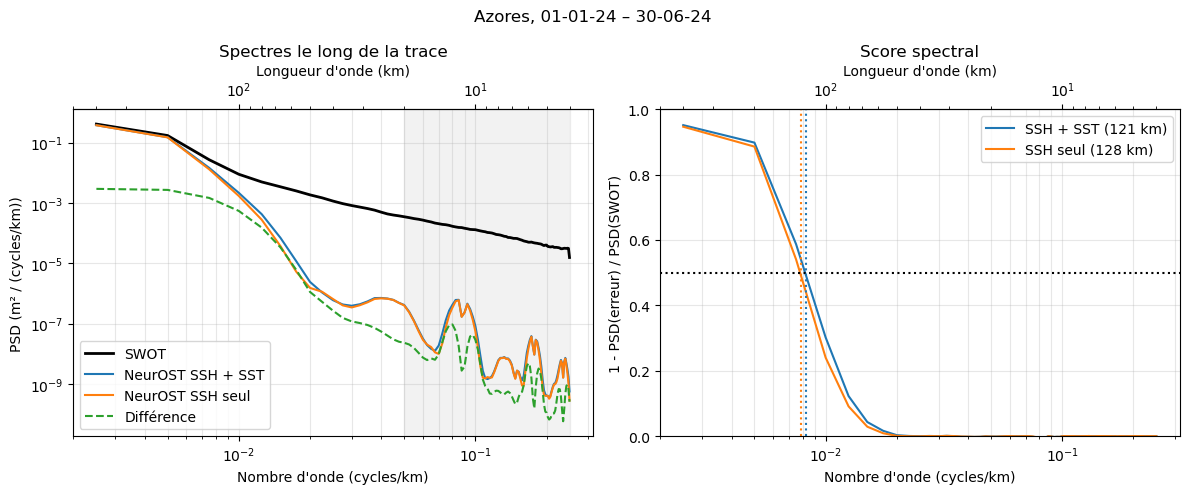

In [19]:
# --------------------------------------------------
# Figure
# --------------------------------------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- panneau 1 : spectres ---
ax1.loglog(k, psd_ref, color='k', lw=2, label="SWOT")
ax1.loglog(k, psd_sst, color='tab:blue', label="NeurOST SSH + SST")
ax1.loglog(k, psd_ssh, color='tab:orange', label="NeurOST SSH seul")
ax1.loglog(k, psd_diff, color='tab:green', ls='--', label="Différence")
#ax1.loglog(k, psd_diff_ssh, color='tab:orange', ls='--', label="Erreur SSH seul")
ax1.set_xlabel("Nombre d'onde (cycles/km)")
ax1.set_ylabel("PSD (m² / (cycles/km))")
ax1.set_title("Spectres le long de la trace")
ax1.legend()
ax1.grid(alpha=0.3, which='both')

ax1.axvspan(1/20, k.max(), color='gray',alpha=0.1)

# --- panneau 2 : scores ---
ax2.semilogx(k, score_sst, color='tab:blue', label=f"SSH + SST ({res_sst:.0f} km)")
ax2.semilogx(k, score_ssh, color='tab:orange', label=f"SSH seul ({res_ssh:.0f} km)")
ax2.axhline(0.5, color='k', ls=':')
ax2.axvline(1 / res_sst, color='tab:blue', ls=':')
ax2.axvline(1 / res_ssh, color='tab:orange', ls=':')
ax2.set_ylim(0, 1)
ax2.set_xlabel("Nombre d'onde (cycles/km)")
ax2.set_ylabel("1 - PSD(erreur) / PSD(SWOT)")
ax2.set_title("Score spectral")
ax2.legend()
ax2.grid(alpha=0.3, which='both')

# axe du haut en longueur d'onde, pour les deux panneaux
for ax in (ax1, ax2):
    haut = ax.secondary_xaxis('top', functions=(lambda x: 1 / x, lambda x: 1 / x))
    haut.set_xlabel("Longueur d'onde (km)")

fig.suptitle(f"Azores, {periode[0]:%d-%m-%y} – {periode[-1]:%d-%m-%y} "
             )
fig.tight_layout()
plt.savefig(f"psd_azo_{periode[0]:%Y%m%d}_{periode[-1]:%Y%m%d}.png", dpi=150)
plt.show()